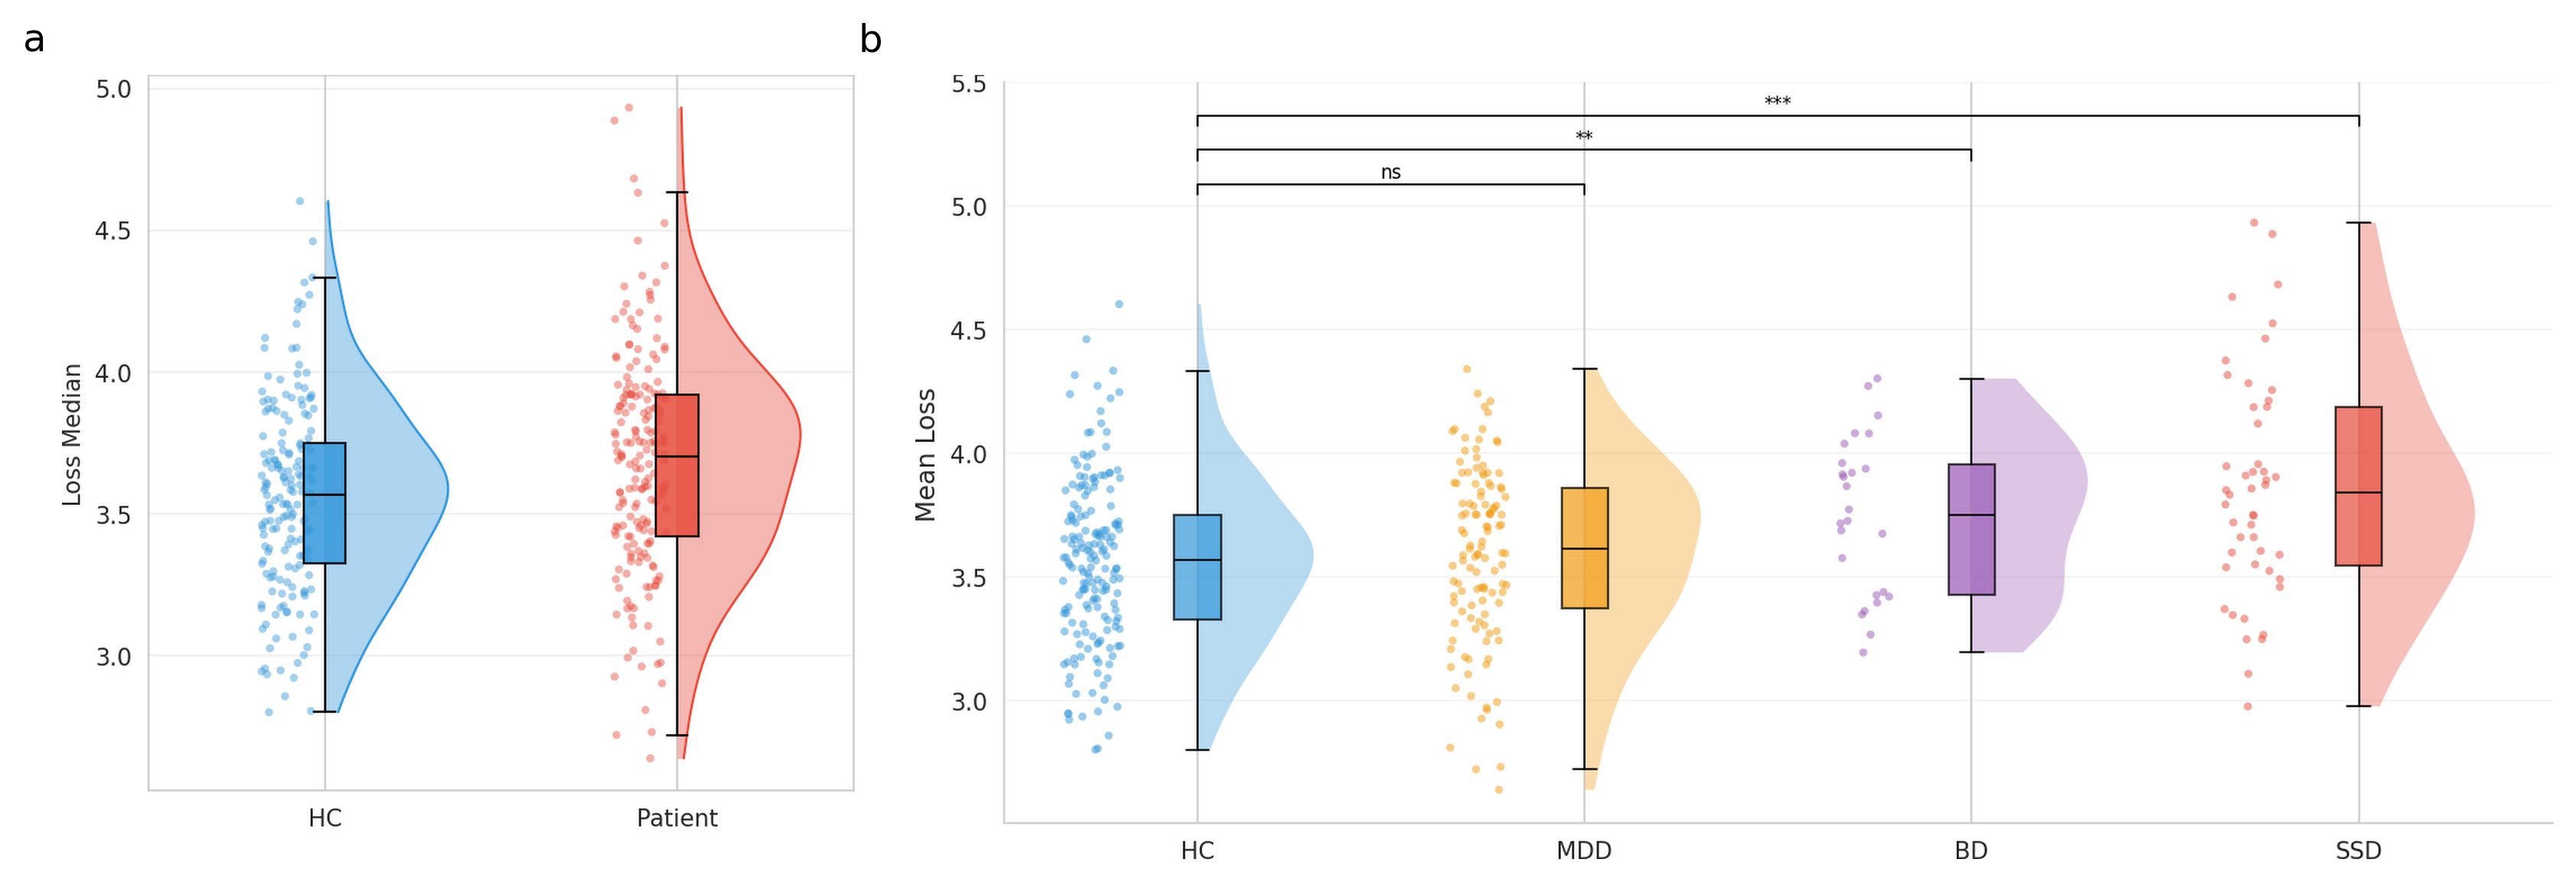

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from pathlib import Path

image_dir = Path("./figures/without_outliers/confounded")

def load_and_crop(path, bg_thresh=0.99):
    """Load PNG, strip surrounding whitespace."""
    img = mpimg.imread(path)
    # RGBA → RGB on white
    if img.ndim == 3 and img.shape[2] == 4:
        img = img[..., :3] * img[..., 3:4] + (1 - img[..., 3:4])
    elif img.dtype == np.uint8:
        img = img.astype(np.float32) / 255.0
    # Find non-white region
    mask = np.any(img < bg_thresh, axis=2)
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    r0, r1 = np.argmax(rows), len(rows) - np.argmax(rows[::-1])
    c0, c1 = np.argmax(cols), len(cols) - np.argmax(cols[::-1])
    return img[r0:r1, c0:c1]

img_a = load_and_crop(image_dir / "group_boxplot_raincloud.png")
img_b = load_and_crop(image_dir / "raincloud_by_diagnosis.png")

# Match heights by padding the shorter image at the bottom
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]
target_h = max(h_a, h_b)

def pad_bottom(img, target_h):
    h, w = img.shape[:2]
    if h < target_h:
        pad = np.ones((target_h - h, w, 3), dtype=img.dtype)
        return np.vstack([img, pad])
    return img

img_a = pad_bottom(img_a, target_h)
img_b = pad_bottom(img_b, target_h)

# Compose side by side with width proportional to original aspect ratios
w_total = 14
ratio_a = w_a / (w_a + w_b)
ratio_b = w_b / (w_a + w_b)

fig, (ax_a, ax_b) = plt.subplots(
    1, 2, figsize=(w_total, 5), dpi=300,
    gridspec_kw={"width_ratios": [ratio_a, ratio_b], "wspace": 0.05},
)
fig.patch.set_facecolor("white")

for ax, img, label in zip([ax_a, ax_b], [img_a, img_b], "ab"):
    ax.imshow(img, interpolation="lanczos", aspect="equal")
    ax.set_axis_off()
    ax.text(-0.02, 1.02, label, transform=ax.transAxes,
            fontsize=12, va="bottom", ha="right")

out = image_dir / "publication" / "composite_figure_2panel.png"
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, dpi=600, bbox_inches="tight", pad_inches=0.02, facecolor="white")
plt.savefig(out.with_suffix(".pdf"), dpi=600, bbox_inches="tight", pad_inches=0.02, facecolor="white")
plt.show()

Saved combined results grid to: figures/00_main_final_tables_figures/combined_main_results_grid_median_loss.png


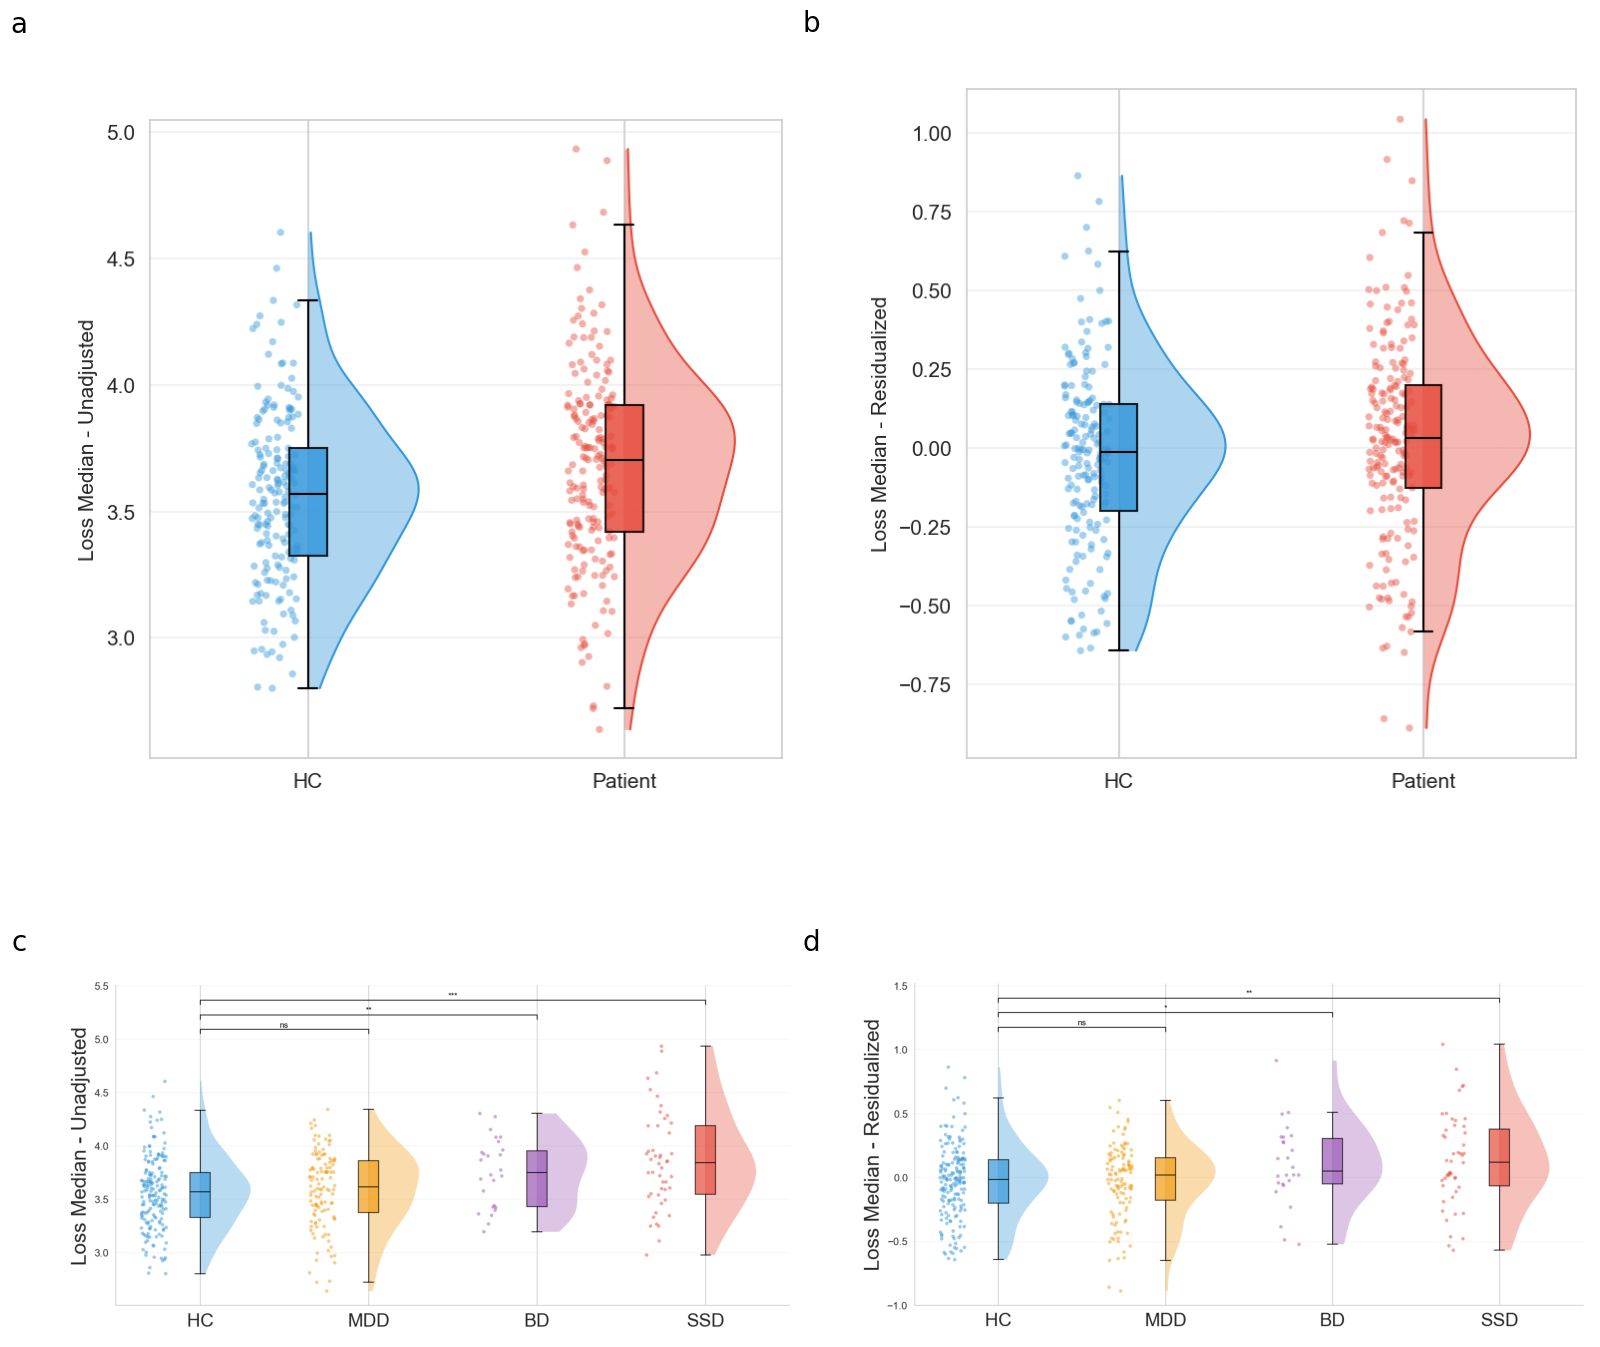

In [4]:
import os
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

fig_dir = "figures/00_main_final_tables_figures/figures"
images = [
    "group_boxplot_raincloud_unadj.png",          
    "group_boxplot_deconfounded_resid.png", 
    "raincloud_by_diagnosis_unadj.png",           
    "raincloud_by_diagnosis_resid.png"      
]

# 1. FIX: Adjust height_ratios. If the bottom row is too small, 
# give it more relative height (e.g., [1, 1.2] means bottom row is 20% taller)
fig, axes = plt.subplots(
    2, 2, 
    figsize=(16, 16), 
    gridspec_kw={'height_ratios': [1, 1]} # <-- Adjust 1.25 up or down as needed
)

panel_labels = ["a", "b", "c", "d"]

for i, img_name in enumerate(images):
    ax = axes[i // 2, i % 2]
    img_path = os.path.join(fig_dir, img_name)
    
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        ax.imshow(img) # Keeps aspect ratio intact
    
    ax.axis('off')  
    
    ax.text(-0.05, 1.05, panel_labels[i], transform=ax.transAxes, 
            fontsize=20, va='bottom', ha='right')

plt.tight_layout()

save_path = "figures/00_main_final_tables_figures/combined_main_results_grid_median_loss.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved combined results grid to: {save_path}")
plt.show()

In [ ]:
import os
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

fig_dir = "figures/00_main_final_tables_figures/figures"
images = [
    "group_boxplot_raincloud_unadj.png",          
    "group_boxplot_deconfounded_resid.png", 
    "raincloud_by_diagnosis_unadj.png",           
    "raincloud_by_diagnosis_resid.png"      
]

# 1. FIX: Adjust height_ratios. If the bottom row is too small, 
# give it more relative height (e.g., [1, 1.2] means bottom row is 20% taller)
fig, axes = plt.subplots(
    2, 2, 
    figsize=(16, 16), 
    gridspec_kw={'height_ratios': [1, 1]} # <-- Adjust 1.25 up or down as needed
)

panel_labels = ["a", "b", "c", "d"]

for i, img_name in enumerate(images):
    ax = axes[i // 2, i % 2]
    img_path = os.path.join(fig_dir, img_name)
    
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        ax.imshow(img) # Keeps aspect ratio intact
    
    ax.axis('off')  
    
    ax.text(-0.05, 1.05, panel_labels[i], transform=ax.transAxes, 
            fontsize=20, va='bottom', ha='right')

plt.tight_layout()

save_path = "figures/00_main_final_tables_figures/combined_main_results_grid_median_loss.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved combined results grid to: {save_path}")
plt.show()

In [ ]:
import os
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

# Directories
SOURCE_DIR = "figures/advanced"
OUTPUT_DIR = "figures/00_main_final_tables_figures/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# The four ROC curves we generated in our loop
images = [
    "comprehensive_incremental_value_roc_all.png",  # Panel a (All Patients)
    "comprehensive_incremental_value_roc_ssd.png",  # Panel b (Schizophrenia Spectrum)
    "comprehensive_incremental_value_roc_bd.png",   # Panel c (Bipolar Disorder)
    "comprehensive_incremental_value_roc_mdd.png"   # Panel d (Major Depression)
]

# Set up the 2x2 grid (16x16 is perfect to keep text legible and crisp)
fig, axes = plt.subplots(
    2, 2, 
    figsize=(16, 16), 
    gridspec_kw={'height_ratios': [1, 1]} # Uniform height
)

panel_labels = ["a", "b", "c", "d"]
panel_titles = [
    "All Patients vs. HC", 
    "SSD vs. HC", 
    "BD vs. HC", 
    "MDD vs. HC"
]

for i, img_name in enumerate(images):
    ax = axes[i // 2, i % 2]
    img_path = os.path.join(SOURCE_DIR, img_name)
    
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        ax.imshow(img)  # Keeps aspect ratio fully intact
    else:
        print(f"Warning: {img_path} not found.")
        
    ax.axis('off')  # Hide grid axes for clean image rendering
    
    # Place panel labels (a, b, c, d) in the top-left corner
    ax.text(-0.02, 1.02, panel_labels[i], transform=ax.transAxes, 
            fontsize=24, fontweight='bold', va='bottom', ha='right')

# Use tight_layout to eliminate excess white spaces between panels
plt.tight_layout(pad=1.0)

save_path = os.path.join(OUTPUT_DIR, "combined_comprehensive_roc_grid.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\nSaved combined ROC results grid to: {save_path}")
plt.show()

: 